In [37]:
import pandas as pd
import numpy as np

# Standardization function
def standard_scaler(x_data, X_column):
    mean = np.mean(X_column)
    std_dev = np.std(X_column)
    return (x_data - mean) / std_dev


# Load dataset
data = pd.read_csv('logistic.csv')

# Replace 'B' with 0 and 'M' with 1 in the Y column
data['Y'] = data['Y'].replace({'B': 0, 'M': 1})

# Split data (80% train, 20% test)
train_data = data.sample(frac=0.8, random_state=42)
test_data = data.drop(train_data.index)

# Separate features and target variable before standardization
X_train = train_data.drop(columns='Y')
y_train = train_data['Y'].values
X_test = test_data.drop(columns='Y')
y_test = test_data['Y'].values

# Standardize the features only (do not standardize the target)
X_train_standardized = pd.DataFrame()
for column in X_train.columns:
    X_train_standardized[column] = standard_scaler(X_train[column].values, X_train[column])

X_test_standardized = pd.DataFrame()
for column in X_test.columns:
    X_test_standardized[column] = standard_scaler(X_test[column].values, X_test[column])

# Convert standardized data to numpy arrays for training
X_train = X_train_standardized.values
X_test = X_test_standardized.values

In [38]:
class LogisticRegression:
    def __init__(self, lr=0.001, n_iter=1000, batch_size=32, seed=42, reg_type=None, reg_lambda=0.0):
        np.random.seed(seed)
        self.lr = lr
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.weights = None
        self.bias = 0
        self.reg_type = reg_type  # None, 'L1', or 'L2'
        self.reg_lambda = reg_lambda  # Regularization strength

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Initialize weights
        self.weights = np.zeros(n_features)
        
        # Optimize weights using Stochastic Gradient Descent
        self.stochastic_gradient_descent(X, y)

    def stochastic_gradient_descent(self, X, y):
        for i in range(self.n_iter):
            # Sample mini-batch
            idx = np.random.randint(0, X.shape[0], self.batch_size)
            X_batch, y_batch = X[idx], y[idx]
            
            # Calculate predictions and gradients
            y_pred = self.sigmoid(np.dot(X_batch, self.weights) + self.bias)
            gradient = np.dot(X_batch.T, (y_pred - y_batch)) / self.batch_size

            # Add regularization
            if self.reg_type == 'L2':
                gradient += self.reg_lambda * self.weights
            elif self.reg_type == 'L1':
                gradient += self.reg_lambda * np.sign(self.weights)

            # Update weights and bias
            self.weights -= self.lr * gradient
            self.bias -= self.lr * np.sum(y_pred - y_batch) / self.batch_size

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)
        return [1 if i > 0.5 else 0 for i in y_predicted]


In [39]:
class Loss:
    def __init__(self, X, y, reg_type=None, reg_lambda=0.0):
        self.X = X
        self.y = y
        self.reg_type = reg_type
        self.reg_lambda = reg_lambda
    
    # Cross-Entropy Loss with optional L1/L2 regularization
    def cross_entropy_loss(self, w):
        predictions = self.sigmoid(np.dot(self.X, w))
        loss = -np.mean(self.y * np.log(predictions + 1e-8) + (1 - self.y) * np.log(1 - predictions + 1e-8))
        
        # Apply regularization
        if self.reg_type == 'L2':
            loss += self.reg_lambda * np.sum(w ** 2) / 2
        elif self.reg_type == 'L1':
            loss += self.reg_lambda * np.sum(np.abs(w))
        
        return loss

    def cross_entropy_loss_gradient(self, w):
        predictions = self.sigmoid(np.dot(self.X, w))
        gradient = np.dot(self.X.T, (predictions - self.y)) / len(self.y)
        
        # Apply regularization
        if self.reg_type == 'L2':
            gradient += self.reg_lambda * w
        elif self.reg_type == 'L1':
            gradient += self.reg_lambda * np.sign(w)
        
        return gradient


In [40]:
# Cross-Entropy Loss with SGD
model_ce_sgd = LogisticRegression(lr=0.01, n_iter=1000, batch_size=32)
model_ce_sgd.fit(X_train, y_train)

# L1-Regularized Cross-Entropy Loss with SGD
model_l1_sgd = LogisticRegression(lr=0.01, n_iter=1000, batch_size=32, reg_type='L1', reg_lambda=0.1)
model_l1_sgd.fit(X_train, y_train)

# L2-Regularized Cross-Entropy Loss with SGD
model_l2_sgd = LogisticRegression(lr=0.01, n_iter=1000, batch_size=32, reg_type='L2', reg_lambda=0.1)
model_l2_sgd.fit(X_train, y_train)


In [41]:
from sklearn.metrics import log_loss

def backward_feature_selection(X, y, model):
    remaining_features = list(range(X.shape[1]))
    best_features = remaining_features.copy()
    best_aic = np.inf

    while len(remaining_features) > 0:
        aic_scores = []
        
        for feature in remaining_features:
            temp_features = [f for f in remaining_features if f != feature]
            X_temp = X[:, temp_features]
            model.fit(X_temp, y)
            y_pred = model.predict(X_temp)
            aic = 2 * len(temp_features) + 2 * log_loss(y, y_pred)
            aic_scores.append((feature, aic))

        # Select the feature with the smallest AIC
        worst_feature, worst_aic = min(aic_scores, key=lambda x: x[1])
        
        # If removing this feature improves AIC, do it
        if worst_aic < best_aic:
            best_aic = worst_aic
            best_features.remove(worst_feature)
            remaining_features = best_features.copy()
        else:
            break

    return best_features


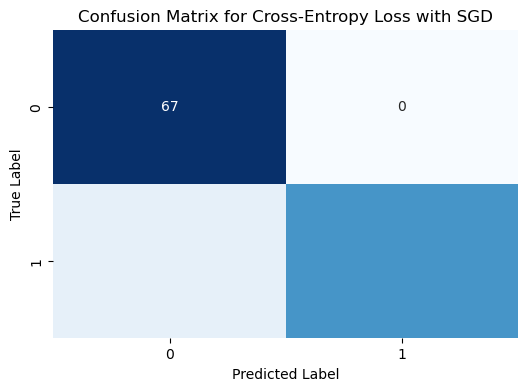

Metrics for Cross-Entropy:
Train Accuracy: 0.9824175824175824
Test Accuracy: 0.9473684210526315
Precision: 1.0
Recall: 0.8723404255319149
F1-Score: 0.9318181818181819
Confusion Matrix: [[67  0]
 [ 6 41]]

Metrics for L1-Regularized:
Train Accuracy: 0.9384615384615385
Test Accuracy: 0.9122807017543859
Precision: 1.0
Recall: 0.7872340425531915
F1-Score: 0.880952380952381
Confusion Matrix: [[67  0]
 [10 37]]

Metrics for L2-Regularized:
Train Accuracy: 0.978021978021978
Test Accuracy: 0.9473684210526315
Precision: 1.0
Recall: 0.8723404255319149
F1-Score: 0.9318181818181819
Confusion Matrix: [[67  0]
 [ 6 41]]



In [42]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate and plot for each model
models = [model_ce_sgd, model_l1_sgd, model_l2_sgd]
labels = ['Cross-Entropy', 'L1-Regularized', 'L2-Regularized']
results = {}

for model, label in zip(models, labels):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    # Compute and store metrics
    train_accuracy = accuracy_score(y_train, y_pred_train)
    test_accuracy = accuracy_score(y_test, y_pred_test)
    precision = precision_score(y_test, y_pred_test)
    recall = recall_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test)
    conf_matrix = confusion_matrix(y_test, y_pred_test)

    results[label] = {
        'Train Accuracy': train_accuracy,
        'Test Accuracy': test_accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Confusion Matrix': conf_matrix
    }

    # Plot confusion matrix for Cross-Entropy with SGD
    if label == 'Cross-Entropy':
        plt.figure(figsize=(6, 4))
        sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title("Confusion Matrix for Cross-Entropy Loss with SGD")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.show()

# Display metrics
for label, metrics in results.items():
    print(f"Metrics for {label}:")
    for metric, value in metrics.items():
        print(f"{metric}: {value}")
    print()

    

In [43]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define Logistic Regression with L2-Regularization and Gradient Descent
class L2LogisticRegression:
    def __init__(self, alpha, lambda_reg, n_iter=1000, seed=42):
        np.random.seed(seed)
        self.alpha = alpha  # Step length
        self.lambda_reg = lambda_reg  # L2 regularization parameter
        self.n_iter = n_iter
        self.weights = None
        self.bias = 0

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        
        # Gradient Descent with L2 regularization
        for _ in range(self.n_iter):
            linear_model = np.dot(X, self.weights) + self.bias
            y_pred = self.sigmoid(linear_model)
            gradient = (np.dot(X.T, (y_pred - y)) / n_samples) + (self.lambda_reg * self.weights)
            
            # Update weights and bias
            self.weights -= self.alpha * gradient
            self.bias -= self.alpha * np.sum(y_pred - y) / n_samples

    def predict(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        y_predicted = self.sigmoid(linear_model)
        return [1 if i > 0.5 else 0 for i in y_predicted]

# K-Fold Cross-Validation and Grid Search
def k_fold_grid_search(X, y, alphas, lambdas, k=3):
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    results = []
    
    for alpha in alphas:
        for lambda_reg in lambdas:
            accuracies = []
            
            for train_index, val_index in kf.split(X):
                X_train, X_val = X[train_index], X[val_index]
                y_train, y_val = y[train_index], y[val_index]
                
                # Train model with the current hyperparameters
                model = L2LogisticRegression(alpha=alpha, lambda_reg=lambda_reg)
                model.fit(X_train, y_train)
                y_val_pred = model.predict(X_val)
                
                # Compute accuracy for current fold
                accuracy = accuracy_score(y_val, y_val_pred)
                accuracies.append(accuracy)
            
            # Average accuracy across folds
            mean_accuracy = np.mean(accuracies)
            results.append((alpha, lambda_reg, mean_accuracy))
    
    # Find best hyperparameter combination
    best_alpha, best_lambda, best_accuracy = max(results, key=lambda x: x[2])
    return best_alpha, best_lambda, best_accuracy, results


In [49]:
def plot_hyperparameter_grid(results):
    alphas, lambdas, accuracies = zip(*results)
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(alphas, lambdas, accuracies, c=accuracies, cmap='viridis')
    ax.set_xlabel("Alpha (Step Length)")
    ax.set_ylabel("Lambda (Regularization)")
    ax.set_zlabel("Accuracy")
    plt.title("Hyperparameter Grid Search")
    plt.show()


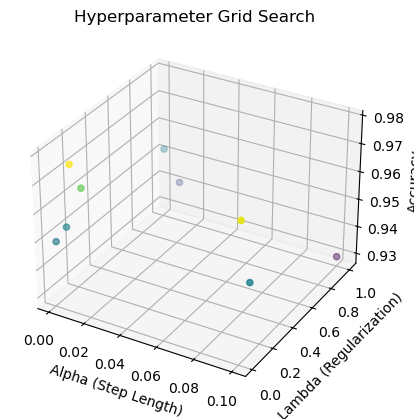

Final Test Accuracy: 0.95


In [50]:
# Define hyperparameter grid
alphas = [0.001, 0.01, 0.1]
lambdas = [0.01, 0.1, 1.0]
X = X_train_standardized.values  # Convert DataFrame to numpy array
y = train_data['Y'].values       # Target as numpy array

# Perform grid search with 3-fold cross-validation
best_alpha, best_lambda, best_accuracy, results = k_fold_grid_search(X, y, alphas, lambdas)

# Plot grid search results
plot_hyperparameter_grid(results)

# Train final model with best hyperparameters on the full dataset
final_model = L2LogisticRegression(alpha=best_alpha, lambda_reg=best_lambda)
final_model.fit(X, y)

# Evaluate on test set
X_test_np = X_test_standardized.values  # Convert test set to numpy array
y_test_pred = final_model.predict(X_test_np)
final_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Final Test Accuracy: {final_accuracy:.2f}")


In [46]:
def l1_regularized_loss(X, y, w, lambda_reg):
    predictions = np.dot(X, w)
    residuals = predictions - y
    mse_loss = np.mean(residuals ** 2)
    l1_penalty = lambda_reg * np.sum(np.abs(w))
    return mse_loss + l1_penalty


In [47]:
def coordinate_descent_l1(X, y, lambda_reg, n_iter=1000, tol=1e-6):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    
    for _ in range(n_iter):
        w_old = w.copy()
        
        for j in range(n_features):
            # Calculate residual excluding the current feature
            residual = y - (np.dot(X, w) - X[:, j] * w[j])
            
            # Compute update for w[j]
            rho_j = np.dot(X[:, j], residual) / n_samples
            
            # Soft-thresholding operator for L1 penalty
            if rho_j < -lambda_reg:
                w[j] = (rho_j + lambda_reg)
            elif rho_j > lambda_reg:
                w[j] = (rho_j - lambda_reg)
            else:
                w[j] = 0

        # Check for convergence
        if np.linalg.norm(w - w_old, ord=1) < tol:
            break
    return w


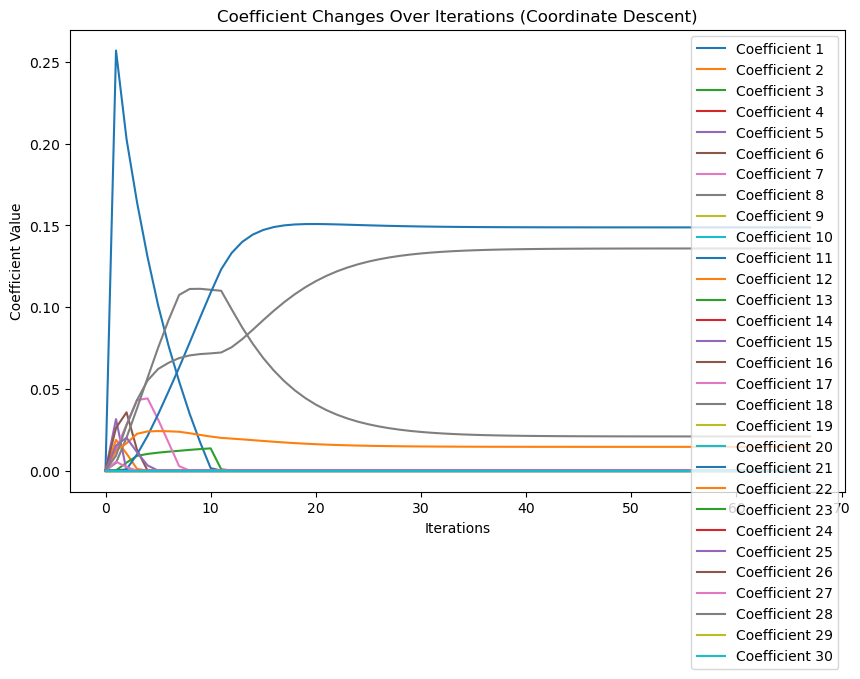

In [48]:
def coordinate_descent_l1_with_tracking(X, y, lambda_reg, n_iter=1000, tol=1e-6):
    n_samples, n_features = X.shape
    w = np.zeros(n_features)
    weight_history = []

    for _ in range(n_iter):
        w_old = w.copy()
        weight_history.append(w.copy())
        
        for j in range(n_features):
            residual = y - (np.dot(X, w) - X[:, j] * w[j])
            rho_j = np.dot(X[:, j], residual) / n_samples
            
            if rho_j < -lambda_reg:
                w[j] = (rho_j + lambda_reg)
            elif rho_j > lambda_reg:
                w[j] = (rho_j - lambda_reg)
            else:
                w[j] = 0

        if np.linalg.norm(w - w_old, ord=1) < tol:
            break
    weight_history.append(w.copy())
    return w, weight_history

# Plot coefficient changes over iterations
final_weights, weight_history = coordinate_descent_l1_with_tracking(X, y, lambda_reg=0.1)
weight_history = np.array(weight_history)

plt.figure(figsize=(10, 6))
for j in range(weight_history.shape[1]):
    plt.plot(weight_history[:, j], label=f'Coefficient {j+1}')
plt.xlabel("Iterations")
plt.ylabel("Coefficient Value")
plt.title("Coefficient Changes Over Iterations (Coordinate Descent)")
plt.legend()
plt.show()
